<center><h1>Li_Ruifeng_HW5</h1></center>
<br>
<br>


Name: Ruifeng Li
<br>
Github Username: Lrf8182
<br>
USC ID: 3072841010


## 1. Decision Trees as Interpretable Models


Import packages


In [1]:
import math
import re
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from IPython.display import display
from sklearn.decomposition import PCA
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LassoCV, LinearRegression, Ridge
from sklearn.metrics import mean_squared_error
from sklearn.model_selection import GridSearchCV, KFold, StratifiedKFold, cross_val_score
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.tree import DecisionTreeClassifier, _tree, export_text, plot_tree
from xgboost import XGBRegressor

RANDOM_STATE = 42
CV = KFold(n_splits=10, shuffle=True, random_state=RANDOM_STATE)

sns.set_theme(style="whitegrid")
pd.set_option("display.max_rows", 200)
pd.set_option("display.max_columns", 30)


def locate_data_dir():
    candidates = [Path.cwd(), Path.cwd() / "week5"]
    for folder in candidates:
        if (folder / "diagnosis.data").exists() and (folder / "communities.data").exists():
            return folder
    raise FileNotFoundError("Could not find diagnosis.data and communities.data in the working directory or week5/.")


DATA_DIR = locate_data_dir()


def regression_mse(model, X_tr, y_tr, X_te, y_te, name):
    train_mse = mean_squared_error(y_tr, model.predict(X_tr))
    test_mse = mean_squared_error(y_te, model.predict(X_te))
    print(f"{name} training MSE: {train_mse:.6f}")
    print(f"{name} test MSE:     {test_mse:.6f}")
    return train_mse, test_mse


def tree_to_code(model, feature_names):
    """Python-3 form of the KDnuggets tree walk. Each leaf returns the predicted diagnosis."""
    tree_ = model.tree_
    feature_name = [
        feature_names[i] if i != _tree.TREE_UNDEFINED else "undefined!"
        for i in tree_.feature
    ]
    print("def tree({}):".format(", ".join(feature_names)))

    def recurse(node, depth):
        indent = "  " * depth
        if tree_.feature[node] != _tree.TREE_UNDEFINED:
            name = feature_name[node]
            threshold = tree_.threshold[node]
            print(f"{indent}if {name} <= {threshold:.4f}:")
            recurse(tree_.children_left[node], depth + 1)
            print(f"{indent}else:  # if {name} > {threshold:.4f}")
            recurse(tree_.children_right[node], depth + 1)
        else:
            class_id = int(np.argmax(tree_.value[node][0]))
            label = str(model.classes_[class_id])
            count = int(tree_.n_node_samples[node])
            print(f"{indent}return {label!r}  # {count} patients")

    recurse(0, 1)


def if_then_rules(model, feature_names, binary_features):
    """One IF-THEN rule per leaf. Binary splits are written as yes or no."""
    tree_ = model.tree_
    binary_features = set(binary_features)
    rules = []

    def recurse(node, conditions):
        if tree_.feature[node] == _tree.TREE_UNDEFINED:
            class_id = int(np.argmax(tree_.value[node][0]))
            label = str(model.classes_[class_id])
            count = int(tree_.n_node_samples[node])
            rules.append((conditions, label, count))
            return
        name = feature_names[tree_.feature[node]]
        threshold = tree_.threshold[node]
        if name in binary_features:
            recurse(tree_.children_left[node], conditions + [f"{name} = no"])
            recurse(tree_.children_right[node], conditions + [f"{name} = yes"])
        else:
            recurse(tree_.children_left[node], conditions + [f"{name} <= {threshold:.2f}"])
            recurse(tree_.children_right[node], conditions + [f"{name} > {threshold:.2f}"])

    recurse(0, [])
    lines = []
    for index, (conditions, label, count) in enumerate(rules, start=1):
        noun = "patient" if count == 1 else "patients"
        lines.append(
            f"Rule {index}: IF {' AND '.join(conditions)} THEN {label}  ({count} {noun})"
        )
    return lines


### (a) Obtain Data


The Acute Inflammations data set is stored in `diagnosis.data`. Each of the 120 rows is a potential patient. The six attributes are body temperature and five yes/no symptoms. The two decision labels are inflammation of the urinary bladder and nephritis of renal pelvis origin, so the problem is multi-label. The file is tab-separated UTF-16, and temperature uses a comma as the decimal mark. The documentation states that there are no missing values.


In [2]:
symptom_columns = [
    "Temperature",
    "Nausea",
    "Lumbar pain",
    "Urine pushing",
    "Micturition pains",
    "Burning of urethra",
]
label_columns = ["Bladder inflammation", "Nephritis"]

diagnosis = pd.read_csv(
    DATA_DIR / "diagnosis.data",
    sep="\t",
    header=None,
    names=symptom_columns + label_columns,
    encoding="utf-16",
)
diagnosis["Temperature"] = (
    diagnosis["Temperature"].astype(str).str.replace(",", ".", regex=False).astype(float)
)

print(f"Shape: {diagnosis.shape}")
print("Missing values:", int(diagnosis.isna().sum().sum()))
display(diagnosis.head(8))
print("Joint diagnoses:")
display(diagnosis.groupby(label_columns).size().rename("patients").reset_index())


Shape: (120, 8)
Missing values: 0


,Temperature,Nausea,Lumbar pain,Urine pushing,Micturition pains,Burning of urethra,Bladder inflammation,Nephritis
0,35.5,no,yes,no,no,no,no,no
1,35.9,no,no,yes,yes,yes,yes,no
2,35.9,no,yes,no,no,no,no,no
3,36.0,no,no,yes,yes,yes,yes,no
4,36.0,no,yes,no,no,no,no,no
5,36.0,no,yes,no,no,no,no,no
6,36.2,no,no,yes,yes,yes,yes,no
7,36.2,no,yes,no,no,no,no,no


Joint diagnoses:


,Bladder inflammation,Nephritis,patients
0,no,no,30
1,no,yes,31
2,yes,no,40
3,yes,yes,19


### (b) Build a decision tree


The footnote asks whether the label-powerset method is the right way to handle the two diagnoses. It is. All four combinations occur (30 neither, 40 bladder only, 31 nephritis only, 19 both), so the powerset has four classes and stays small enough for one readable tree. The two diseases are dependent: nephritis goes with high fever and lumbar pain, and the two diseases occur together only in a narrower symptom pattern. One tree on the joint label writes both decisions in the same rule. Binary relevance would hide that dependence in two separate trees.

Yes/no symptoms are coded 1 for yes and 0 for no. The tree uses information gain (`criterion="entropy"`), matching the decision-rule article cited in part (c), and it is fit to the whole data set.


Training accuracy: 1.000
Depth: 4
Leaves: 6

|--- Temperature <= 37.95
|   |--- Urine pushing <= 0.50
|   |   |--- weights: [0.00, 0.00, 0.00, 20.00] class: no bladder, no nephritis
|   |--- Urine pushing >  0.50
|   |   |--- weights: [0.00, 40.00, 0.00, 0.00] class: bladder, no nephritis
|--- Temperature >  37.95
|   |--- Lumbar pain <= 0.50
|   |   |--- weights: [0.00, 0.00, 0.00, 10.00] class: no bladder, no nephritis
|   |--- Lumbar pain >  0.50
|   |   |--- Nausea <= 0.50
|   |   |   |--- weights: [0.00, 0.00, 21.00, 0.00] class: no bladder, nephritis
|   |   |--- Nausea >  0.50
|   |   |   |--- Urine pushing <= 0.50
|   |   |   |   |--- weights: [0.00, 0.00, 10.00, 0.00] class: no bladder, nephritis
|   |   |   |--- Urine pushing >  0.50
|   |   |   |   |--- weights: [19.00, 0.00, 0.00, 0.00] class: bladder, nephritis



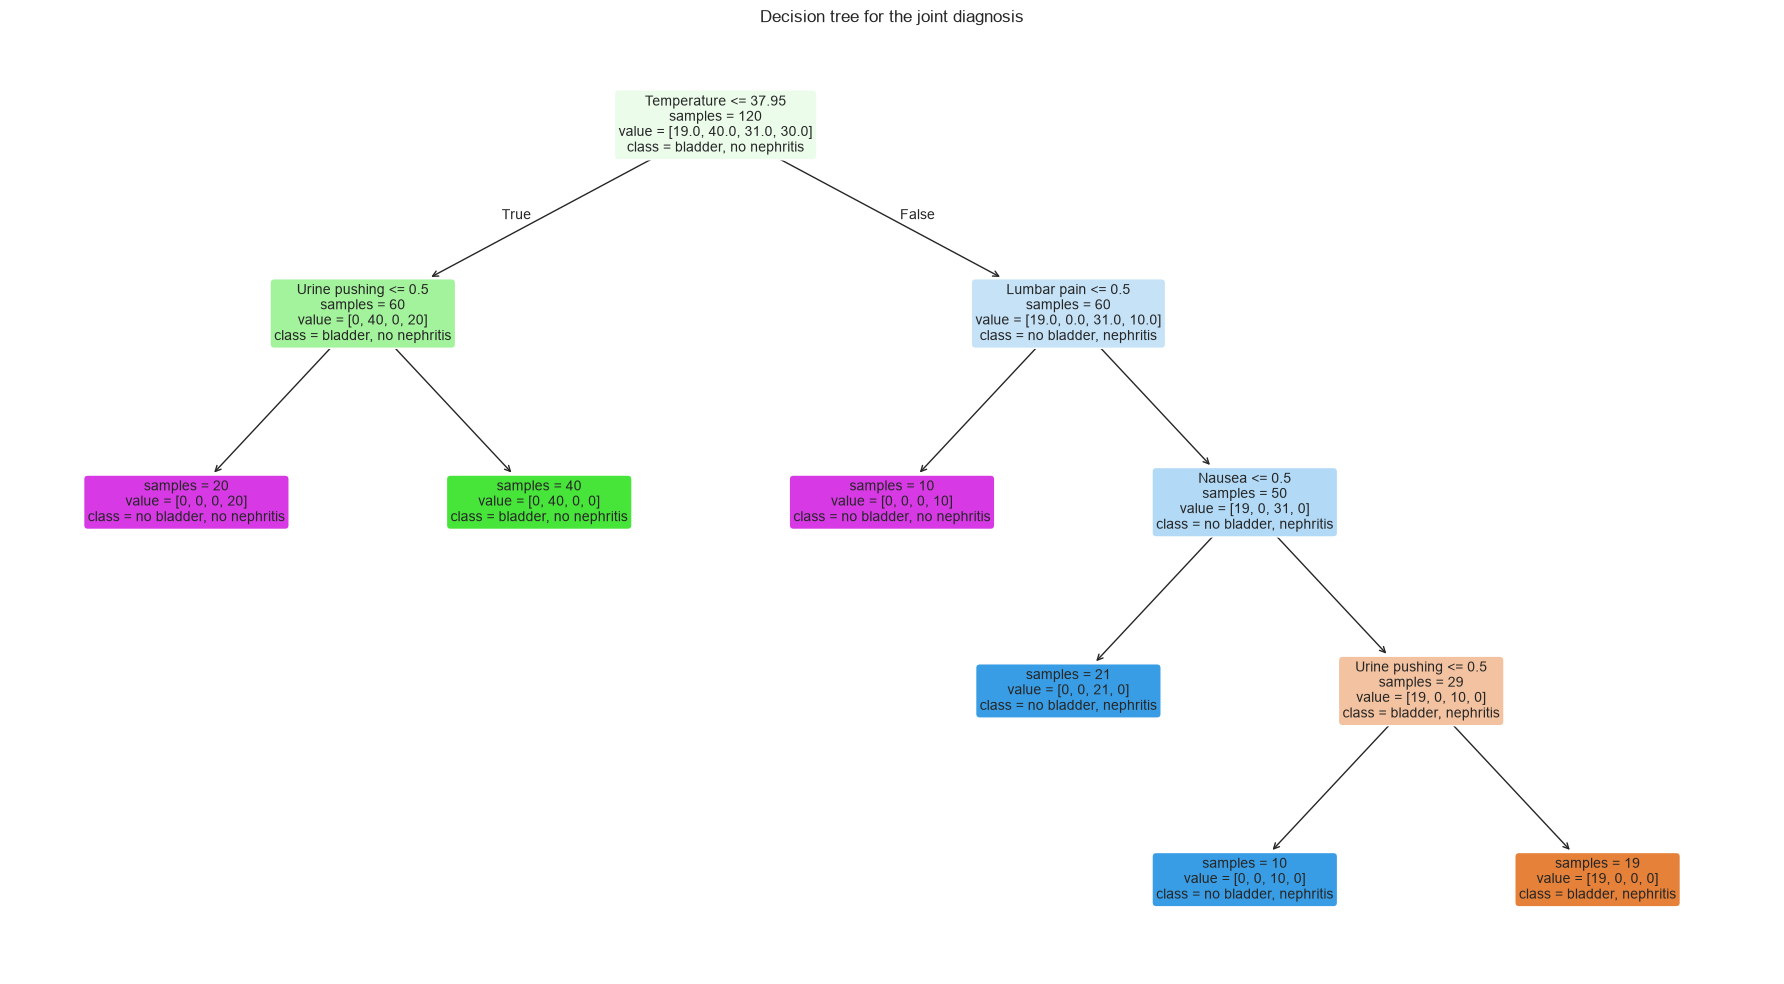

In [3]:
binary_features = [
    "Nausea",
    "Lumbar pain",
    "Urine pushing",
    "Micturition pains",
    "Burning of urethra",
]
X_diag = diagnosis[symptom_columns].copy()
for column in binary_features:
    X_diag[column] = (diagnosis[column] == "yes").astype(int)

y_diag = np.where(
    diagnosis["Bladder inflammation"] == "yes", "bladder", "no bladder"
) + ", " + np.where(diagnosis["Nephritis"] == "yes", "nephritis", "no nephritis")

tree = DecisionTreeClassifier(criterion="entropy", random_state=RANDOM_STATE)
tree.fit(X_diag, y_diag)

print(f"Training accuracy: {tree.score(X_diag, y_diag):.3f}")
print(f"Depth: {tree.get_depth()}")
print(f"Leaves: {tree.get_n_leaves()}")
print()
print(export_text(tree, feature_names=symptom_columns, decimals=2, show_weights=True))

fig, ax = plt.subplots(figsize=(18, 10))
plot_tree(
    tree,
    feature_names=symptom_columns,
    class_names=list(tree.classes_),
    filled=True,
    rounded=True,
    impurity=False,
    fontsize=10,
    ax=ax,
)
ax.set_title("Decision tree for the joint diagnosis")
plt.tight_layout()
plt.show()


### (c) Convert the decision rules


The rules below come from the same root-to-leaf walk as the KDnuggets `tree_to_code` routine. The first block is that routine in Python 3, with the leaf written as the predicted diagnosis. The second block is the same tree as one IF-THEN rule per leaf. A binary split at 0.5 is written as yes or no.


In [4]:
print("Nested form")
tree_to_code(tree, symptom_columns)
print()
print("IF-THEN rules")
for rule in if_then_rules(tree, symptom_columns, binary_features):
    print(rule)


Nested form
def tree(Temperature, Nausea, Lumbar pain, Urine pushing, Micturition pains, Burning of urethra):
  if Temperature <= 37.9500:
    if Urine pushing <= 0.5000:
      return 'no bladder, no nephritis'  # 20 patients
    else:  # if Urine pushing > 0.5000
      return 'bladder, no nephritis'  # 40 patients
  else:  # if Temperature > 37.9500
    if Lumbar pain <= 0.5000:
      return 'no bladder, no nephritis'  # 10 patients
    else:  # if Lumbar pain > 0.5000
      if Nausea <= 0.5000:
        return 'no bladder, nephritis'  # 21 patients
      else:  # if Nausea > 0.5000
        if Urine pushing <= 0.5000:
          return 'no bladder, nephritis'  # 10 patients
        else:  # if Urine pushing > 0.5000
          return 'bladder, nephritis'  # 19 patients

IF-THEN rules
Rule 1: IF Temperature <= 37.95 AND Urine pushing = no THEN no bladder, no nephritis  (20 patients)
Rule 2: IF Temperature <= 37.95 AND Urine pushing = yes THEN bladder, no nephritis  (40 patients)
Rule 3: I

The tree is already small. It uses temperature, urine pushing, lumbar pain, and nausea. Micturition pains and burning of the urethra are not needed to separate these 120 patients. The split at 37.95°C sits on the boundary described in the data file: bladder inflammation is usually not accompanied by fever above 38°C, while nephritis begins with a high fever. Reading the leaves:

- At or below 37.95°C, urine pushing decides bladder inflammation, and nephritis is absent.
- Above 37.95°C, nephritis is present only when lumbar pain is present.
- Both diseases are predicted only when the fever is high, lumbar pain and nausea are present, and urine pushing is present.


### (d) Cost-complexity pruning


Cost-complexity pruning trades training error for a smaller tree. For a tree T the pruned criterion is the impurity of T plus α times the number of leaves. The path below is computed on the whole data set, because parts (b) and (c) describe that tree rather than a held-out split. The minimal interpretable tree is the smallest tree that still classifies every patient correctly. Five-fold stratified accuracy is shown next to the training accuracy so the choice is also checked out of sample.


,ccp_alpha,leaves,depth,train_accuracy,cv_accuracy
0,0.000000,6,4,1.000000,1.000000
1,0.199592,4,2,0.841667,0.866667
2,0.325011,3,2,0.758333,0.766667
3,0.459148,2,1,0.591667,0.633333
4,0.770426,1,0,0.333333,0.433333


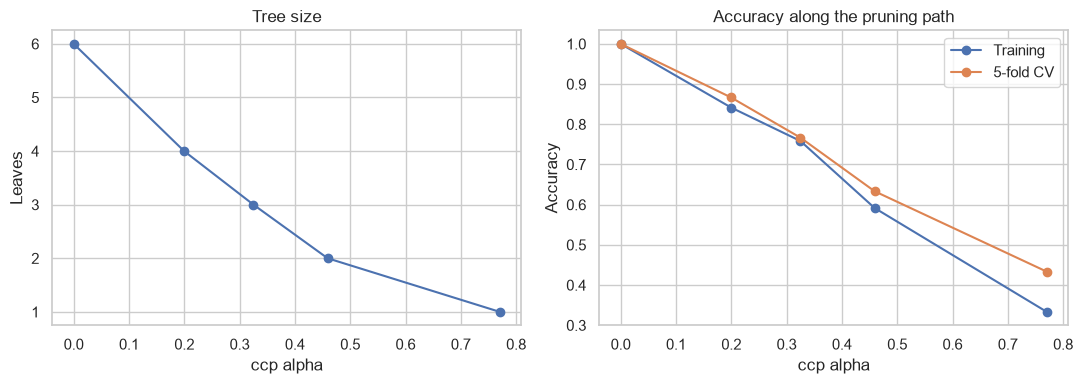

Selected alpha = 0: 6 leaves, training accuracy 1.000, CV accuracy 1.000.
This is the smallest tree on the path that still classifies every patient correctly.

The next tree on the path has alpha = 0.199592, 4 leaves, training accuracy 0.842, and CV accuracy 0.867.
Its rules collapse the two nephritis leaves, so patients with both diseases are labeled nephritis only:

Rule 1: IF Temperature <= 37.95 AND Urine pushing = no THEN no bladder, no nephritis  (20 patients)
Rule 2: IF Temperature <= 37.95 AND Urine pushing = yes THEN bladder, no nephritis  (40 patients)
Rule 3: IF Temperature > 37.95 AND Lumbar pain = no THEN no bladder, no nephritis  (10 patients)
Rule 4: IF Temperature > 37.95 AND Lumbar pain = yes THEN no bladder, nephritis  (50 patients)

The minimal accurate tree is the tree from part (b). Its IF-THEN rules are the rules in part (c).


In [5]:
path = tree.cost_complexity_pruning_path(X_diag, y_diag)
ccp_alphas = path.ccp_alphas
stratified = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

pruning_rows = []
pruned_models = []
for alpha in ccp_alphas:
    pruned = DecisionTreeClassifier(
        criterion="entropy",
        random_state=RANDOM_STATE,
        ccp_alpha=float(alpha),
    )
    pruned.fit(X_diag, y_diag)
    cv_accuracy = cross_val_score(pruned, X_diag, y_diag, cv=stratified).mean()
    pruning_rows.append(
        {
            "ccp_alpha": alpha,
            "leaves": pruned.get_n_leaves(),
            "depth": pruned.get_depth(),
            "train_accuracy": pruned.score(X_diag, y_diag),
            "cv_accuracy": cv_accuracy,
        }
    )
    pruned_models.append(pruned)

pruning_table = pd.DataFrame(pruning_rows)
display(pruning_table)

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].plot(pruning_table["ccp_alpha"], pruning_table["leaves"], marker="o")
axes[0].set_xlabel("ccp alpha")
axes[0].set_ylabel("Leaves")
axes[0].set_title("Tree size")
axes[1].plot(pruning_table["ccp_alpha"], pruning_table["train_accuracy"], marker="o", label="Training")
axes[1].plot(pruning_table["ccp_alpha"], pruning_table["cv_accuracy"], marker="o", label="5-fold CV")
axes[1].set_xlabel("ccp alpha")
axes[1].set_ylabel("Accuracy")
axes[1].set_title("Accuracy along the pruning path")
axes[1].legend()
plt.tight_layout()
plt.show()

perfect = pruning_table["train_accuracy"].max()
candidates = pruning_table[np.isclose(pruning_table["train_accuracy"], perfect)]
chosen_row = candidates.sort_values(["leaves", "ccp_alpha"]).iloc[0]
chosen_alpha = float(chosen_row["ccp_alpha"])
minimal_tree = pruned_models[int(chosen_row.name)]

print(
    f"Selected alpha = {chosen_alpha:.6g}: {int(chosen_row['leaves'])} leaves, "
    f"training accuracy {chosen_row['train_accuracy']:.3f}, "
    f"CV accuracy {chosen_row['cv_accuracy']:.3f}."
)
print("This is the smallest tree on the path that still classifies every patient correctly.")
print()

next_pruned = pruning_table[pruning_table["leaves"] < chosen_row["leaves"]].sort_values(
    "leaves", ascending=False
).iloc[0]
print(
    f"The next tree on the path has alpha = {next_pruned['ccp_alpha']:.6g}, "
    f"{int(next_pruned['leaves'])} leaves, training accuracy {next_pruned['train_accuracy']:.3f}, "
    f"and CV accuracy {next_pruned['cv_accuracy']:.3f}."
)
print("Its rules collapse the two nephritis leaves, so patients with both diseases are labeled nephritis only:")
print()
for rule in if_then_rules(pruned_models[int(next_pruned.name)], symptom_columns, binary_features):
    print(rule)

print()
if minimal_tree.get_n_leaves() == tree.get_n_leaves() and np.isclose(chosen_alpha, 0.0):
    print("The minimal accurate tree is the tree from part (b). Its IF-THEN rules are the rules in part (c).")
else:
    print("IF-THEN rules for the selected pruned tree:")
    for rule in if_then_rules(minimal_tree, symptom_columns, binary_features):
        print(rule)


Any positive α on this path removes leaves and drops training accuracy from 1.00 to 0.842. The four-leaf tree predicts nephritis alone for every high-fever patient with lumbar pain, so the 19 patients who have both diseases are labeled as nephritis only. Five-fold accuracy moves the same way, from 1.00 to 0.867. The six-leaf tree is the minimal rule set that keeps both diagnoses intact, and it is already easy to read.


## 2. The LASSO and Boosting for Regression


### (a) Obtain Data


The Communities and Crime data are in `communities.data`, with attribute names in `communities.names`. The file has 1,994 communities and 128 attributes. As specified, the first 1,495 rows are the training set and the remaining 499 rows are the test set. The split follows the file order.


In [6]:
attribute_names = []
with open(DATA_DIR / "communities.names", encoding="latin-1") as names_file:
    for line in names_file:
        match = re.match(r"@attribute\s+(\S+)", line.strip())
        if match:
            attribute_names.append(match.group(1))

communities = pd.read_csv(
    DATA_DIR / "communities.data",
    header=None,
    names=attribute_names,
    na_values="?",
)
print(f"Attributes listed: {len(attribute_names)}")
print(f"Data shape: {communities.shape}")

TARGET = "ViolentCrimesPerPop"
train_df = communities.iloc[:1495].copy()
test_df = communities.iloc[1495:].copy()
print(f"Training rows: {len(train_df)}")
print(f"Test rows: {len(test_df)}")
display(communities.head(3))


Attributes listed: 128
Data shape: (1994, 128)
Training rows: 1495
Test rows: 499


,state,county,community,communityname,fold,population,householdsize,racepctblack,racePctWhite,racePctAsian,racePctHisp,agePct12t21,agePct12t29,agePct16t24,agePct65up,...,PctPolicAsian,PctPolicMinor,OfficAssgnDrugUnits,NumKindsDrugsSeiz,PolicAveOTWorked,LandArea,PopDens,PctUsePubTrans,PolicCars,PolicOperBudg,LemasPctPolicOnPatr,LemasGangUnitDeploy,LemasPctOfficDrugUn,PolicBudgPerPop,ViolentCrimesPerPop
0,8,NaN,NaN,Lakewoodcity,1,0.19,0.33,0.02,0.90,0.12,0.17,0.34,0.47,0.29,0.32,...,0.1,0.07,0.02,0.57,0.29,0.12,0.26,0.20,0.06,0.04,0.9,0.5,0.32,0.14,0.20
1,53,NaN,NaN,Tukwilacity,1,0.00,0.16,0.12,0.74,0.45,0.07,0.26,0.59,0.35,0.27,...,NaN,NaN,NaN,NaN,NaN,0.02,0.12,0.45,NaN,NaN,NaN,NaN,0.00,NaN,0.67
2,24,NaN,NaN,Aberdeentown,1,0.00,0.42,0.49,0.56,0.17,0.04,0.39,0.47,0.28,0.32,...,NaN,NaN,NaN,NaN,NaN,0.01,0.21,0.02,NaN,NaN,NaN,NaN,0.00,NaN,0.43


### (b) Missing values


The data description marks five attributes as nonpredictive: `state`, `county`, `community`, `communityname`, and `fold`. Those columns are dropped. The quantity to predict is `ViolentCrimesPerPop`.

Missing entries are stored as `?`. Twenty-two law-enforcement (LEMAS) attributes are missing for most communities, because that survey did not cover every department, and `OtherPerCap` is missing once. The missing entries are replaced by the column mean. The mean is computed on the training set and then applied to the test set. After this step a LEMAS column is constant on the many rows that were missing, so those columns carry less information than a fully observed feature. They are still kept, because the assignment asks for imputation rather than deletion.


In [7]:
nonpredictive = ["state", "county", "community", "communityname", "fold"]
feature_columns = [column for column in communities.columns if column not in nonpredictive + [TARGET]]

X_train = train_df[feature_columns].copy()
X_test = test_df[feature_columns].copy()
y_train = train_df[TARGET].copy()
y_test = test_df[TARGET].copy()

missing_counts = X_train.isna().sum()
missing_counts = missing_counts[missing_counts > 0].sort_values(ascending=False)
missing_table = pd.DataFrame(
    {
        "training_missing": missing_counts,
        "training_missing_fraction": missing_counts / len(X_train),
        "test_missing": X_test.isna().sum().loc[missing_counts.index],
    }
)
print(f"Predictive features: {len(feature_columns)}")
print(f"Training target missing: {int(y_train.isna().sum())}")
print(f"Test target missing: {int(y_test.isna().sum())}")
display(missing_table)

imputer = SimpleImputer(strategy="mean")
X_train_imp = pd.DataFrame(
    imputer.fit_transform(X_train),
    columns=feature_columns,
    index=X_train.index,
)
X_test_imp = pd.DataFrame(
    imputer.transform(X_test),
    columns=feature_columns,
    index=X_test.index,
)
print("Missing values after imputation:", int(X_train_imp.isna().sum().sum() + X_test_imp.isna().sum().sum()))


Predictive features: 122
Training target missing: 0
Test target missing: 0


,training_missing,training_missing_fraction,test_missing
LemasSwornFT,1256,0.840134,419
LemasSwFTPerPop,1256,0.840134,419
LemasSwFTFieldOps,1256,0.840134,419
LemasTotalReq,1256,0.840134,419
LemasSwFTFieldPerPop,1256,0.840134,419
LemasTotReqPerPop,1256,0.840134,419
PolicReqPerOffic,1256,0.840134,419
OfficAssgnDrugUnits,1256,0.840134,419
PolicPerPop,1256,0.840134,419
RacialMatchCommPol,1256,0.840134,419


Missing values after imputation: 0


### (c) Plot a correlation matrix


The matrix is the Pearson correlation of the 122 imputed predictive features on the training set. The test set is not included. Labels are small because there are 122 of them; the table under the figure lists the strongest pairs.


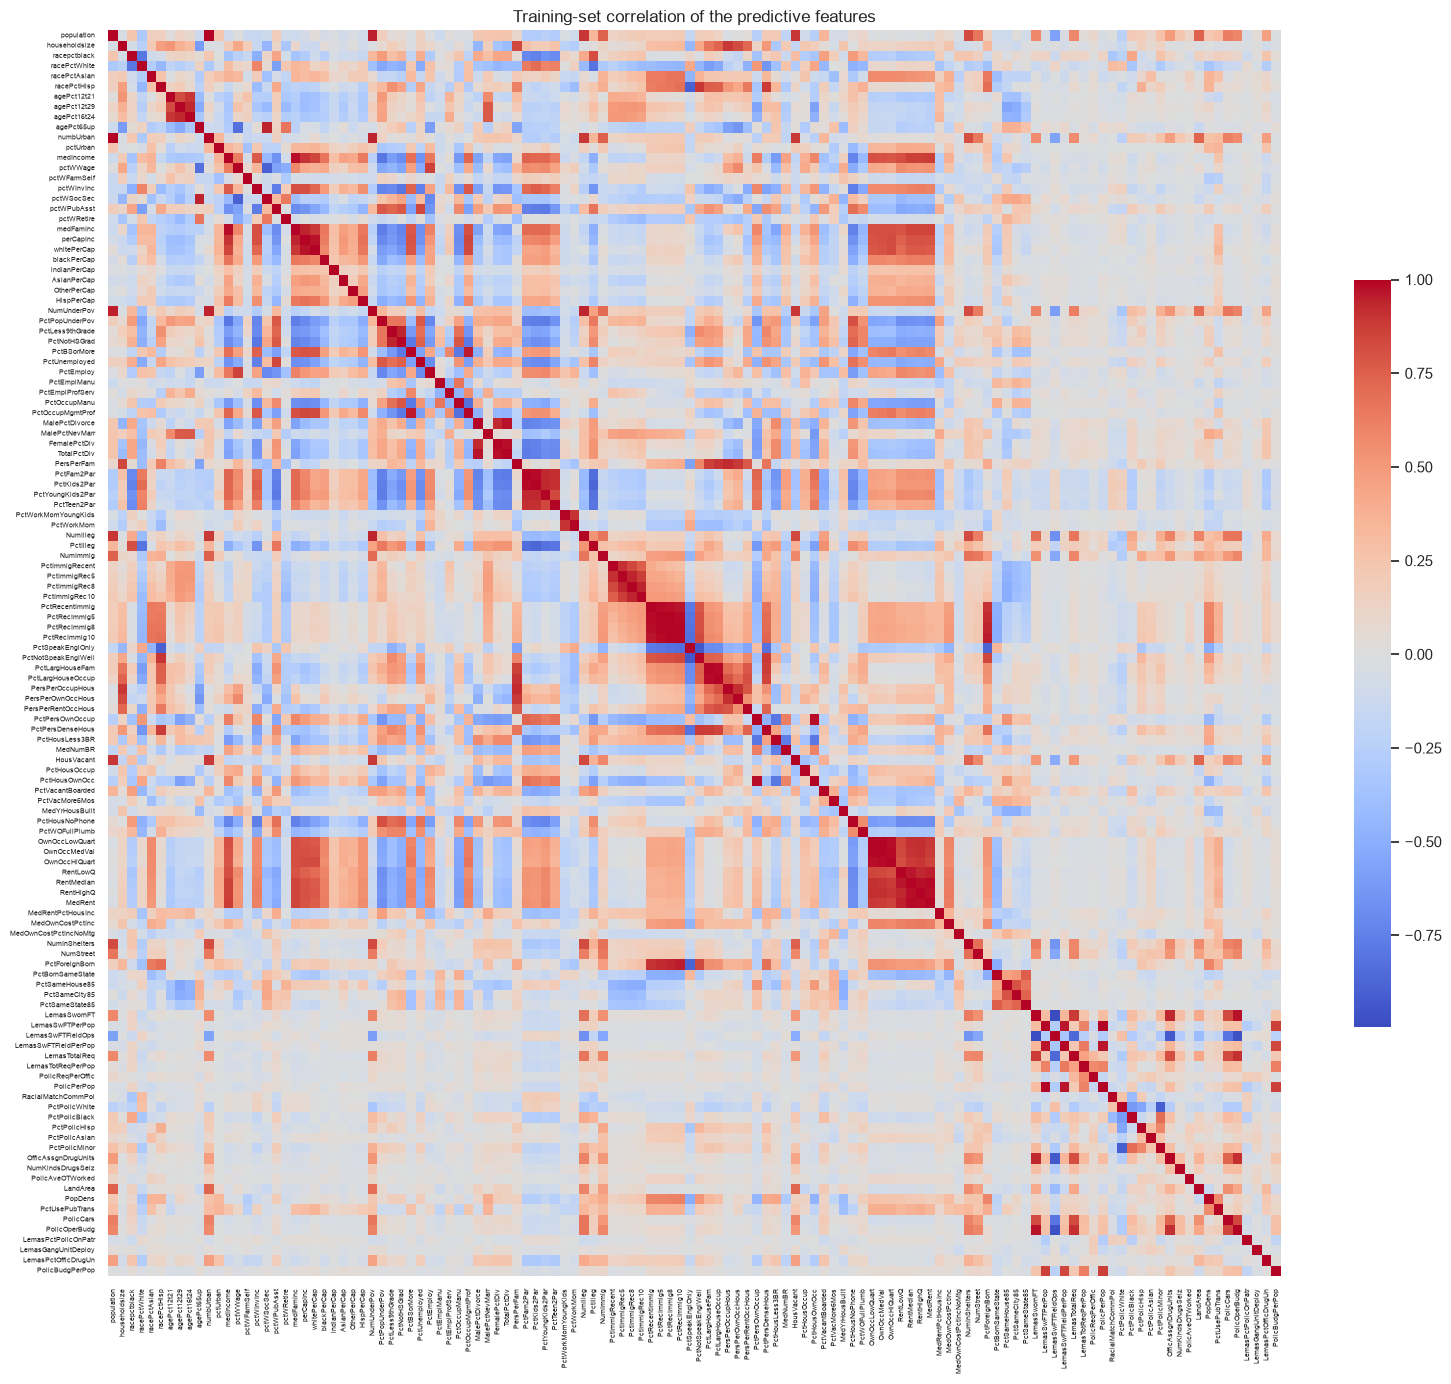

,feature_1,feature_2,correlation
0,LemasSwFTPerPop,PolicPerPop,1.000000
1,PctRecImmig8,PctRecImmig10,0.995561
2,OwnOccLowQuart,OwnOccMedVal,0.994692
3,LemasSwornFT,LemasSwFTFieldOps,-0.993998
4,population,numbUrban,0.993613
5,PctRecImmig5,PctRecImmig8,0.992735
6,OwnOccMedVal,OwnOccHiQuart,0.991559
7,PctRecentImmig,PctRecImmig5,0.989361
8,RentMedian,MedRent,0.988780
9,PctFam2Par,PctKids2Par,0.985623


In [8]:
correlation = X_train_imp.corr()

fig, ax = plt.subplots(figsize=(16, 14))
sns.heatmap(
    correlation,
    cmap="coolwarm",
    center=0,
    xticklabels=True,
    yticklabels=True,
    cbar_kws={"shrink": 0.6},
    ax=ax,
)
ax.tick_params(axis="both", labelsize=5)
ax.set_title("Training-set correlation of the predictive features")
plt.tight_layout()
plt.show()

pair_rows = []
for i, left in enumerate(feature_columns):
    for right in feature_columns[i + 1 :]:
        pair_rows.append((left, right, correlation.loc[left, right]))
pair_table = pd.DataFrame(pair_rows, columns=["feature_1", "feature_2", "correlation"])
pair_table["absolute_correlation"] = pair_table["correlation"].abs()
pair_table = pair_table.sort_values("absolute_correlation", ascending=False).head(15)
pair_table = pair_table.drop(columns="absolute_correlation")
display(pair_table.reset_index(drop=True))


The strongest pairs are near duplicates. Police officers per population matches another sworn-officer rate exactly. Immigration-recency percentages, owner-occupied housing values, population and the urban-population count, rents, and the two-parent family percentages all have correlations above 0.98. Ordinary least squares has to split credit among these overlapping columns. That is the setting in which ridge and the lasso are useful.


### (d) Calculate the Coefficient of Variation CV


For each training feature, CV = s / m, where s is the sample standard deviation (divisor n − 1) and m is the sample mean. CV is computed after imputation.


In [9]:
cv_table = pd.DataFrame(
    {
        "mean": X_train_imp.mean(),
        "std": X_train_imp.std(ddof=1),
    }
)
cv_table["CV"] = cv_table["std"] / cv_table["mean"]
cv_table = cv_table.sort_values("CV", ascending=False)
print("Features with a zero mean:", int(cv_table["mean"].eq(0).sum()))
display(cv_table)


Features with a zero mean: 0


,mean,std,CV
NumStreet,0.022983,0.098665,4.292923
NumInShelters,0.029599,0.102736,3.470952
NumIlleg,0.037204,0.113806,3.058964
NumImmig,0.030595,0.089541,2.926635
LemasPctOfficDrugUn,0.093304,0.238201,2.552946
NumUnderPov,0.056849,0.133167,2.342443
population,0.058167,0.130359,2.241105
numbUrban,0.064649,0.131784,2.038461
HousVacant,0.076475,0.150538,1.968467
LandArea,0.064107,0.105482,1.645408


### (e) Scatter plots and box plots for highest CV features


The assignment asks for the ⌊√128⌋ features with the largest CV. √128 is about 11.31, so that is 11 features. Each scatter plot uses the training-set violent-crime rate on the vertical axis. The box plots use the same 11 features.


Number of features: 11


,mean,std,CV
NumStreet,0.022983,0.098665,4.292923
NumInShelters,0.029599,0.102736,3.470952
NumIlleg,0.037204,0.113806,3.058964
NumImmig,0.030595,0.089541,2.926635
LemasPctOfficDrugUn,0.093304,0.238201,2.552946
NumUnderPov,0.056849,0.133167,2.342443
population,0.058167,0.130359,2.241105
numbUrban,0.064649,0.131784,2.038461
HousVacant,0.076475,0.150538,1.968467
LandArea,0.064107,0.105482,1.645408


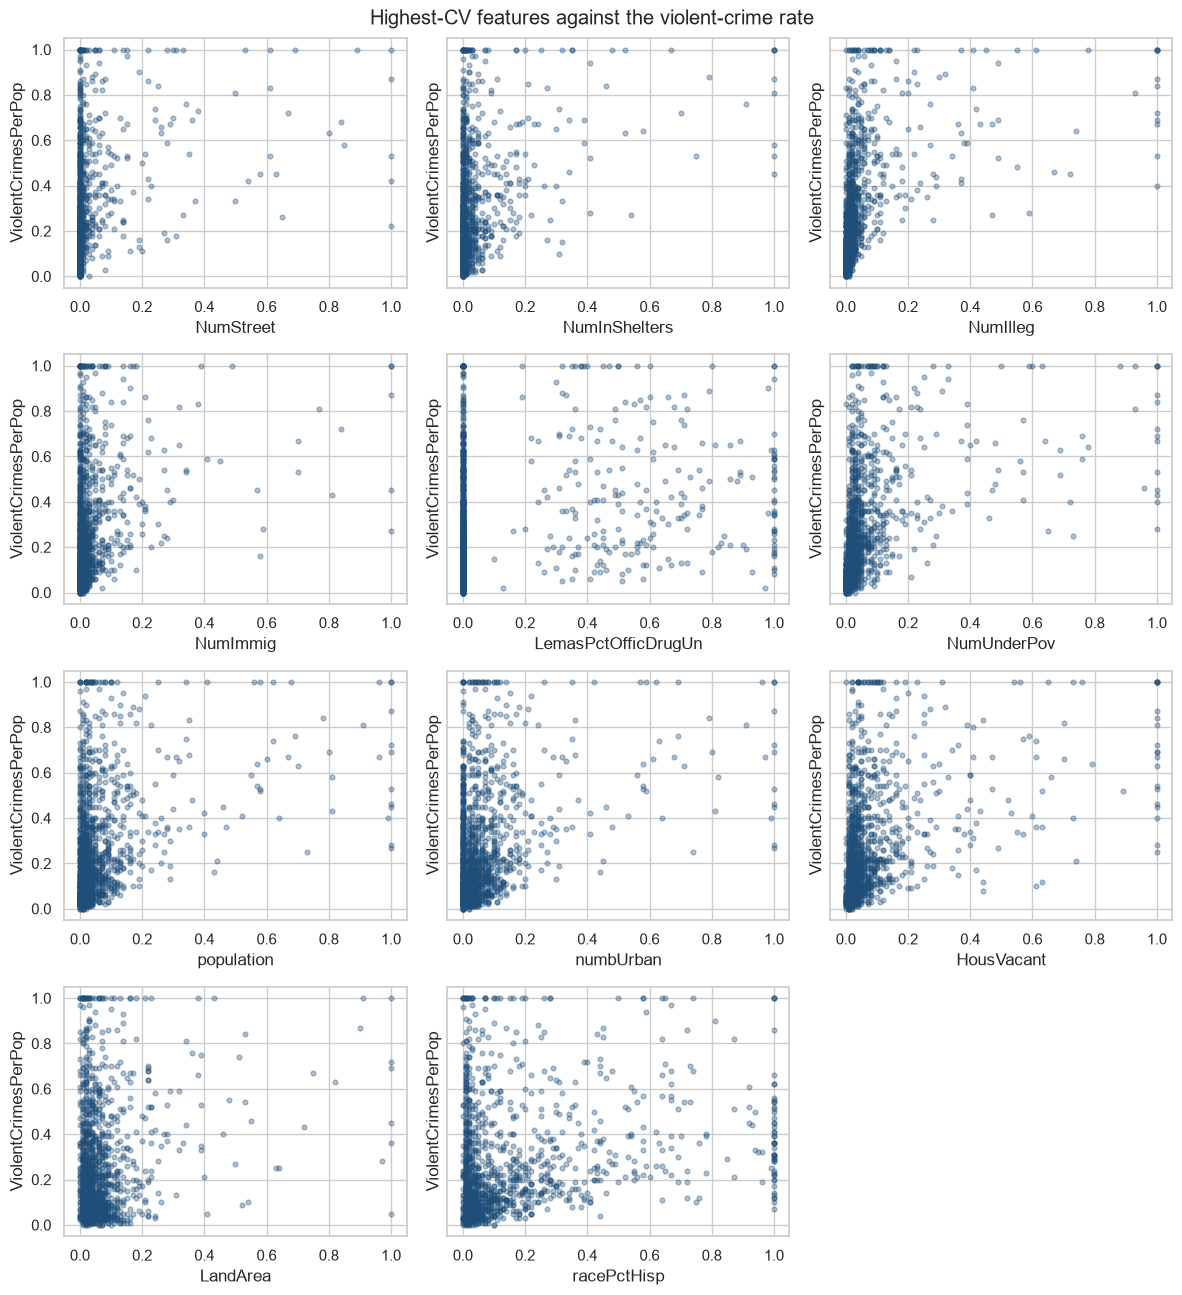

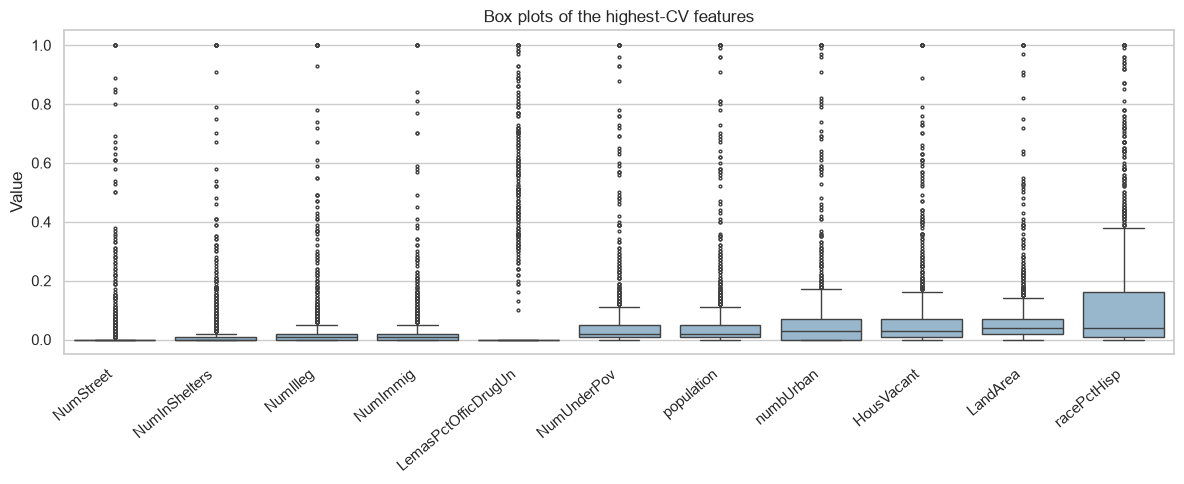

In [10]:
n_high_cv = math.floor(math.sqrt(128))
high_cv_features = cv_table.head(n_high_cv).index.tolist()
print(f"Number of features: {n_high_cv}")
display(cv_table.loc[high_cv_features])

ncols = 3
nrows = math.ceil(n_high_cv / ncols)
fig, axes = plt.subplots(nrows, ncols, figsize=(12, 3.3 * nrows), sharey=True)
for axis, feature in zip(axes.ravel(), high_cv_features):
    axis.scatter(X_train_imp[feature], y_train, s=12, alpha=0.35, color="#1f4e79")
    axis.set_xlabel(feature)
    axis.set_ylabel("ViolentCrimesPerPop")
for axis in axes.ravel()[n_high_cv:]:
    axis.axis("off")
fig.suptitle("Highest-CV features against the violent-crime rate")
fig.tight_layout()
plt.show()

fig, axis = plt.subplots(figsize=(12, 5))
sns.boxplot(data=X_train_imp[high_cv_features], ax=axis, fliersize=2, color="#8fb8d6")
plt.setp(axis.get_xticklabels(), rotation=40, ha="right")
axis.set_ylabel("Value")
axis.set_title("Box plots of the highest-CV features")
plt.tight_layout()
plt.show()


These plots do not establish that the 11 features are significant predictors. CV measures spread relative to the mean. Here the large values belong to sparse, right-skewed columns: street homelessness, shelter population, counts of births and immigrants, population, vacant housing, land area, and a few skewed percentages. Most communities sit near zero and a handful are large, so the standard deviation is several times the mean. The box plots show that same long upper tail.

The scatter plots are a dense clump at the origin with, at most, a loose upward drift. That shape can come from a weak association or from no stable association. A significance claim needs a standard error or a formal test, and a scatter plot supplies neither. A feature can have a very large CV and still add little once other community characteristics are in the model.


### (f) Fit a linear model


The linear model is ordinary least squares, fit on the imputed training set. The test error is the mean squared error of `ViolentCrimesPerPop` on the 499 held-out communities. The response is already scaled to [0, 1], so the MSE is on that scale.


In [11]:
ols = LinearRegression()
ols.fit(X_train_imp, y_train)
ols_train_mse, ols_test_mse = regression_mse(ols, X_train_imp, y_train, X_test_imp, y_test, "Least squares")


Least squares training MSE: 0.016309
Least squares test MSE:     0.018142


### (g) Fit a ridge regression model


Ridge regression minimizes the residual sum of squares plus λ times the squared length of the coefficient vector. In scikit-learn, λ is the parameter `alpha`. It is chosen by 10-fold cross-validation on the training set, using mean squared error. The published features are already normalized to [0, 1], and this part leaves them on that scale. The selected λ is then refit on the full training set and scored on the test set.


Ridge lambda chosen by CV: 2.98247
Ridge training MSE: 0.017107
Ridge test MSE:     0.017563


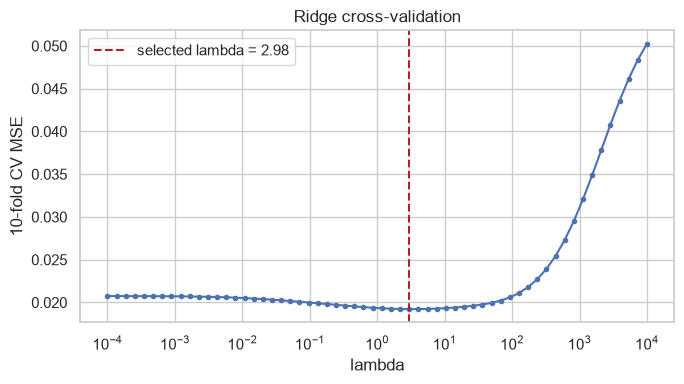

In [12]:
ridge_alphas = np.logspace(-4, 4, 60)
ridge_search = GridSearchCV(
    Ridge(),
    {"alpha": ridge_alphas},
    cv=CV,
    scoring="neg_mean_squared_error",
    n_jobs=-1,
)
ridge_search.fit(X_train_imp, y_train)
ridge = ridge_search.best_estimator_
ridge_alpha = ridge_search.best_params_["alpha"]
print(f"Ridge lambda chosen by CV: {ridge_alpha:.6g}")
ridge_train_mse, ridge_test_mse = regression_mse(ridge, X_train_imp, y_train, X_test_imp, y_test, "Ridge")

fig, axis = plt.subplots(figsize=(7, 4))
axis.semilogx(ridge_alphas, -ridge_search.cv_results_["mean_test_score"], marker="o", ms=3)
axis.axvline(ridge_alpha, color="#b22222", linestyle="--", label=f"selected lambda = {ridge_alpha:.3g}")
axis.set_xlabel("lambda")
axis.set_ylabel("10-fold CV MSE")
axis.set_title("Ridge cross-validation")
axis.legend()
plt.tight_layout()
plt.show()


### (h) Fit a LASSO model


The lasso uses the same training and test matrices and the same 10 folds. λ is chosen along the lasso path by cross-validated mean squared error. A coefficient that is driven to zero is an unselected variable.

The fit is then repeated after standardizing the features to mean 0 and variance 1. Standardization is fit on the training set only. The data are already normalized to [0, 1], but the columns still have different variances, and the L1 penalty depends on those variances.


LASSO lambda: 0.000124541
LASSO training MSE: 0.017024
LASSO test MSE:     0.017737
Selected variables: 75 of 122


,coefficient
racepctblack,0.271286
agePct12t29,-0.250002
PctPersDenseHous,0.213471
PctKids2Par,-0.196721
NumStreet,0.164678
RentLowQ,-0.155000
MedRent,0.154425
PctPopUnderPov,-0.138807
PctEmploy,0.129175
PctWorkMom,-0.127407


Standardized LASSO lambda: 0.000663691
Standardized LASSO training MSE: 0.016948
Standardized LASSO test MSE:     0.017839
Selected variables: 76 of 122


,coefficient
racepctblack,0.068903
PctPersDenseHous,0.043284
agePct12t29,-0.042076
PctKids2Par,-0.040183
RentLowQ,-0.030085
MedRent,0.029339
PctPopUnderPov,-0.028944
PctEmploy,0.024053
PctIlleg,0.023981
MalePctNevMarr,0.023479


In the unstandardized model only: ['LemasPctOfficDrugUn', 'PctBornSameState', 'PctImmigRecent', 'PolicBudgPerPop']
In the standardized model only: ['OfficAssgnDrugUnits', 'PctPolicHisp', 'PctPolicWhite', 'PolicCars', 'population']
Test MSE, original normalization: 0.017737 (75 variables). Test MSE, standardized: 0.017839 (76 variables).


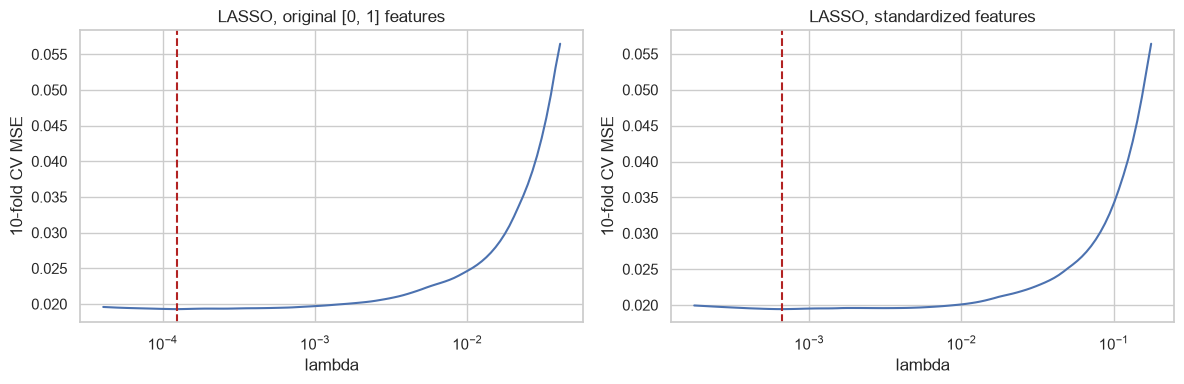

In [13]:
def selected_coefficients(model, columns):
    coefficients = pd.Series(model.coef_, index=columns)
    selected = coefficients[np.abs(coefficients) > 1e-8].sort_values(key=np.abs, ascending=False)
    return selected


lasso = LassoCV(alphas=100, cv=CV, max_iter=50000, random_state=RANDOM_STATE)
lasso.fit(X_train_imp, y_train)
print(f"LASSO lambda: {lasso.alpha_:.6g}")
lasso_train_mse, lasso_test_mse = regression_mse(lasso, X_train_imp, y_train, X_test_imp, y_test, "LASSO")
lasso_selected = selected_coefficients(lasso, feature_columns)
print(f"Selected variables: {len(lasso_selected)} of {len(feature_columns)}")
display(lasso_selected.rename("coefficient").to_frame())

scaler = StandardScaler()
X_train_std = scaler.fit_transform(X_train_imp)
X_test_std = scaler.transform(X_test_imp)
lasso_std = LassoCV(alphas=100, cv=CV, max_iter=50000, random_state=RANDOM_STATE)
lasso_std.fit(X_train_std, y_train)
print(f"Standardized LASSO lambda: {lasso_std.alpha_:.6g}")
lasso_std_train_mse, lasso_std_test_mse = regression_mse(
    lasso_std, X_train_std, y_train, X_test_std, y_test, "Standardized LASSO"
)
lasso_std_selected = selected_coefficients(lasso_std, feature_columns)
print(f"Selected variables: {len(lasso_std_selected)} of {len(feature_columns)}")
display(lasso_std_selected.rename("coefficient").to_frame())

raw_set = set(lasso_selected.index)
std_set = set(lasso_std_selected.index)
print("In the unstandardized model only:", sorted(raw_set - std_set))
print("In the standardized model only:", sorted(std_set - raw_set))
print(
    f"Test MSE, original normalization: {lasso_test_mse:.6f} ({len(raw_set)} variables). "
    f"Test MSE, standardized: {lasso_std_test_mse:.6f} ({len(std_set)} variables)."
)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for axis, model, title in [
    (axes[0], lasso, "LASSO, original [0, 1] features"),
    (axes[1], lasso_std, "LASSO, standardized features"),
]:
    order = np.argsort(model.alphas_)
    axis.semilogx(model.alphas_[order], model.mse_path_.mean(axis=1)[order])
    axis.axvline(model.alpha_, color="#b22222", linestyle="--")
    axis.set_xlabel("lambda")
    axis.set_ylabel("10-fold CV MSE")
    axis.set_title(title)
plt.tight_layout()
plt.show()


The two test errors are close, and the two selected sets overlap on most variables. Standardization puts every column on the same scale before the L1 penalty is applied, so a few variables enter or leave when their variance was unusually small or large on the [0, 1] scale. It does not produce a different prediction error on this test set. The published normalization had already removed the gross differences in units. Both lasso fits also keep a large share of the 122 features: at the λ that minimizes cross-validated error, the penalty is light, because many correlated census variables carry a little predictive signal. A larger λ would make a shorter list and a higher cross-validated error.


### (i) Fit a PCR model


Principal component regression builds the principal components of the predictors and then regresses the response on the first M of them. M is chosen by the same 10-fold cross-validation, minimizing mean squared error. The features are standardized inside each fit before PCA. Normalization to [0, 1] does not equalize variance, and PCA follows the directions of largest variance. The scaler, the PCA, and the linear regression all sit in one pipeline, so the validation fold is not used to estimate the scaling or the components.


M chosen by CV: 96
PCR training MSE: 0.016650
PCR test MSE:     0.018425


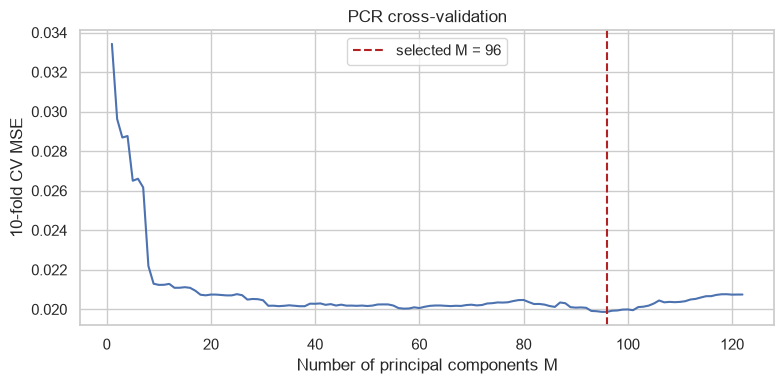

In [14]:
pcr = Pipeline(
    [
        ("scale", StandardScaler()),
        ("pca", PCA(svd_solver="full")),
        ("lr", LinearRegression()),
    ]
)
pcr_search = GridSearchCV(
    pcr,
    {"pca__n_components": list(range(1, X_train_imp.shape[1] + 1))},
    cv=CV,
    scoring="neg_mean_squared_error",
    n_jobs=-1,
)
pcr_search.fit(X_train_imp, y_train)
pcr_model = pcr_search.best_estimator_
pcr_m = pcr_search.best_params_["pca__n_components"]
print(f"M chosen by CV: {pcr_m}")
pcr_train_mse, pcr_test_mse = regression_mse(pcr_model, X_train_imp, y_train, X_test_imp, y_test, "PCR")

component_counts = pcr_search.cv_results_["param_pca__n_components"].astype(int)
cv_mse = -pcr_search.cv_results_["mean_test_score"]
fig, axis = plt.subplots(figsize=(8, 4))
axis.plot(component_counts, cv_mse)
axis.axvline(pcr_m, color="#b22222", linestyle="--", label=f"selected M = {pcr_m}")
axis.set_xlabel("Number of principal components M")
axis.set_ylabel("10-fold CV MSE")
axis.set_title("PCR cross-validation")
axis.legend()
plt.tight_layout()
plt.show()


### (j) Fit a boosting tree


The boosted model is an XGBoost tree ensemble (`booster` defaults to `gbtree`) with squared-error loss. In XGBoost, α is `reg_alpha`, the L1 penalty on the leaf weights. That is the regularization term selected here. The other settings are held fixed: 200 trees, maximum depth 4, learning rate 0.1, row and column subsampling of 0.8, and the default L2 penalty `reg_lambda = 1`. α is chosen by 10-fold cross-validation over a log grid from 10⁻³ to 10. Trees do not need the features to be standardized, and the features are already on [0, 1], so this fit uses the imputed training matrix directly.


alpha chosen by CV: 0.464159
XGBoost training MSE: 0.002304
XGBoost test MSE:     0.015650


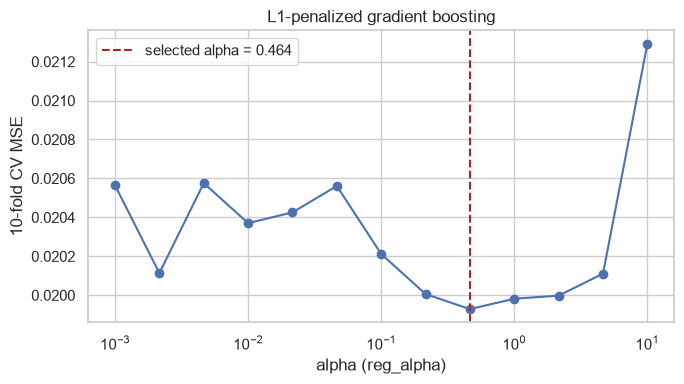

In [15]:
boosting_alphas = np.logspace(-3, 1, 13)
boosting = XGBRegressor(
    n_estimators=200,
    max_depth=4,
    learning_rate=0.1,
    subsample=0.8,
    colsample_bytree=0.8,
    reg_lambda=1.0,
    objective="reg:squarederror",
    tree_method="hist",
    random_state=RANDOM_STATE,
    n_jobs=1,
)
boosting_search = GridSearchCV(
    boosting,
    {"reg_alpha": boosting_alphas},
    cv=CV,
    scoring="neg_mean_squared_error",
    n_jobs=-1,
)
boosting_search.fit(X_train_imp, y_train)
boosting_model = boosting_search.best_estimator_
boosting_alpha = boosting_search.best_params_["reg_alpha"]
print(f"alpha chosen by CV: {boosting_alpha:.6g}")
boosting_train_mse, boosting_test_mse = regression_mse(
    boosting_model, X_train_imp, y_train, X_test_imp, y_test, "XGBoost"
)

fig, axis = plt.subplots(figsize=(7, 4))
axis.semilogx(boosting_alphas, -boosting_search.cv_results_["mean_test_score"], marker="o")
axis.axvline(boosting_alpha, color="#b22222", linestyle="--", label=f"selected alpha = {boosting_alpha:.3g}")
axis.set_xlabel("alpha (reg_alpha)")
axis.set_ylabel("10-fold CV MSE")
axis.set_title("L1-penalized gradient boosting")
axis.legend()
plt.tight_layout()
plt.show()


### Summary of test error


Every test error below is the mean squared error of `ViolentCrimesPerPop` on the same 499 communities. The training MSE is included so the fit to the training set can be compared with the test result.


In [16]:
summary = pd.DataFrame(
    [
        ["Least squares", "—", ols_train_mse, ols_test_mse],
        ["Ridge", f"lambda = {ridge_alpha:.6g}", ridge_train_mse, ridge_test_mse],
        ["LASSO", f"lambda = {lasso.alpha_:.6g}", lasso_train_mse, lasso_test_mse],
        ["LASSO, standardized", f"lambda = {lasso_std.alpha_:.6g}", lasso_std_train_mse, lasso_std_test_mse],
        ["PCR", f"M = {pcr_m}", pcr_train_mse, pcr_test_mse],
        ["XGBoost", f"alpha = {boosting_alpha:.6g}", boosting_train_mse, boosting_test_mse],
    ],
    columns=["Model", "Chosen by CV", "Training MSE", "Test MSE"],
)
summary = summary.sort_values("Test MSE").reset_index(drop=True)
display(summary)


,Model,Chosen by CV,Training MSE,Test MSE
0,XGBoost,alpha = 0.464159,0.002304,0.015650
1,Ridge,lambda = 2.98247,0.017107,0.017563
2,LASSO,lambda = 0.000124541,0.017024,0.017737
3,"LASSO, standardized",lambda = 0.000663691,0.016948,0.017839
4,Least squares,—,0.016309,0.018142
5,PCR,M = 96,0.016650,0.018425


Ridge improves on least squares. The correlation matrix shows why: many predictors are near-copies of one another, and the L2 penalty keeps those coefficients from fitting the training sample as aggressively. The lasso test error is close to the ridge error. Standardizing the features before the lasso changes which variables are kept only at the margin and leaves the test error almost unchanged.

PCR keeps 96 of the 122 components. Its test MSE is 0.018425, slightly above least squares. The crime rate is spread across many components, so shortening the component list does not beat ridge or the lasso on this split.

The boosted tree has a much smaller training error than any linear model. Its test error is the number to compare, and on this split it is the lowest of the six. The gap between its training and test errors is also the largest, which is the usual bias of a deep ensemble: it fits the training communities closely, and the L1 penalty chosen by cross-validation is what keeps that fit from growing further.
